# Grounding DINO Tinyで物体検出

文章で指定した物体を画像から検出し，Bounding Boxと確信度を表示します．このノートブックはCPUだけで動作します．

## 1. ライブラリを読み込む

In [2]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", message="IProgress not found.*")

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from matplotlib.cbook import get_sample_data
from PIL import Image
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor

device = torch.device("cpu")
print("PyTorch:", torch.__version__)
print("使用デバイス:", device)

PyTorch: 2.14.1+cpu
使用デバイス: cpu


## 2. モデルを読み込む

重みはホスト側の `weights/grounding-dino-tiny/` に配置しておきます．

In [3]:
model_path = Path("/weights/grounding-dino-tiny")
required_files = ["config.json", "preprocessor_config.json"]
missing_files = [name for name in required_files if not (model_path / name).is_file()]
has_weights = any((model_path / name).is_file() for name in ("model.safetensors", "pytorch_model.bin"))

if missing_files or not has_weights:
    if not has_weights:
        missing_files.append("model.safetensors または pytorch_model.bin")
    raise FileNotFoundError(
        "モデルファイルが不足しています: " + ", ".join(missing_files) + "\n"
        "READMEを確認し，weights/grounding-dino-tiny/ に重みを配置してください．"
    )

processor = AutoProcessor.from_pretrained(model_path)
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_path).to(device)
model.eval()
print("モデルを読み込みました")

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 2039.50it/s]


モデルを読み込みました


## 3. 画像を用意する

最初はDockerイメージに含まれるサンプル画像を使います．自分の画像を使う場合は，JupyterLabで `notebooks/` に画像を置き，`use_sample_image`を`False`にしてファイル名を変更します．

画像サイズ: (512, 600)


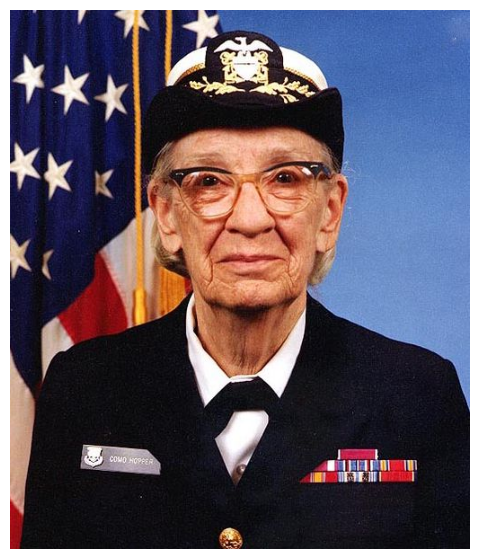

In [4]:
use_sample_image = True
custom_image_path = Path("/workspace/notebooks/your_image.jpg")

if use_sample_image:
    image_path = Path(get_sample_data("grace_hopper.jpg", asfileobj=False))
else:
    image_path = custom_image_path

if not image_path.is_file():
    raise FileNotFoundError(f"画像が見つかりません: {image_path}")

image = Image.open(image_path).convert("RGB")
print("画像サイズ:", image.size)

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")
plt.show()

## 4. 検出処理を定義する

プロンプトには検出したい物体を英語で指定します．複数指定するときは，`person. glasses.`のようにピリオドで区切ります．

In [5]:
def detect_objects(image, text_prompt, box_threshold=0.35, text_threshold=0.25):
    inputs = processor(images=image, text=text_prompt, return_tensors="pt")
    inputs = {name: value.to(device) for name, value in inputs.items()}

    with torch.inference_mode():
        outputs = model(**inputs)

    result = processor.post_process_grounded_object_detection(
        outputs,
        inputs["input_ids"],
        threshold=box_threshold,
        text_threshold=text_threshold,
        target_sizes=[image.size[::-1]],
    )[0]
    return result

## 5. 物体を検出する

In [6]:
text_prompt = "person."
box_threshold = 0.35
text_threshold = 0.25

result = detect_objects(image, text_prompt, box_threshold, text_threshold)
print("検出数:", len(result["boxes"]))

検出数: 1


## 6. 検出結果を表示する

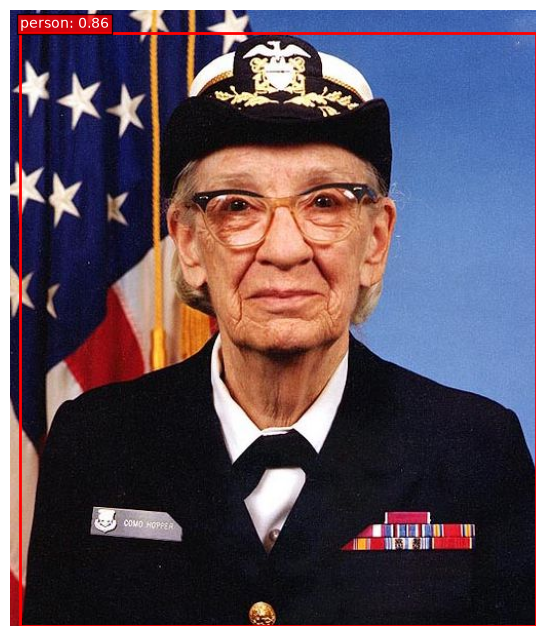

In [7]:
def show_detections(image, result):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image)

    labels = result.get("text_labels", ["object"] * len(result["boxes"]))
    for box, score, label in zip(result["boxes"], result["scores"], labels):
        x_min, y_min, x_max, y_max = box.tolist()
        rectangle = patches.Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            linewidth=2,
            edgecolor="red",
            facecolor="none",
        )
        ax.add_patch(rectangle)
        ax.text(
            x_min,
            max(0, y_min - 5),
            f"{label}: {score:.2f}",
            color="white",
            fontsize=10,
            bbox={"facecolor": "red", "alpha": 0.8, "pad": 2},
        )

    ax.axis("off")
    plt.show()


show_detections(image, result)

## 7. 演習

1. `text_prompt`を`"person. glasses."`に変更し，検出結果を比較してください．
2. `box_threshold`を0.20，0.50に変更し，検出数がどう変わるか確認してください．
3. `use_sample_image = False`に変更し，自分で用意した画像を検出してください．
4. 検出しやすかった物体と検出しにくかった物体を記録してください．

検出数: 2


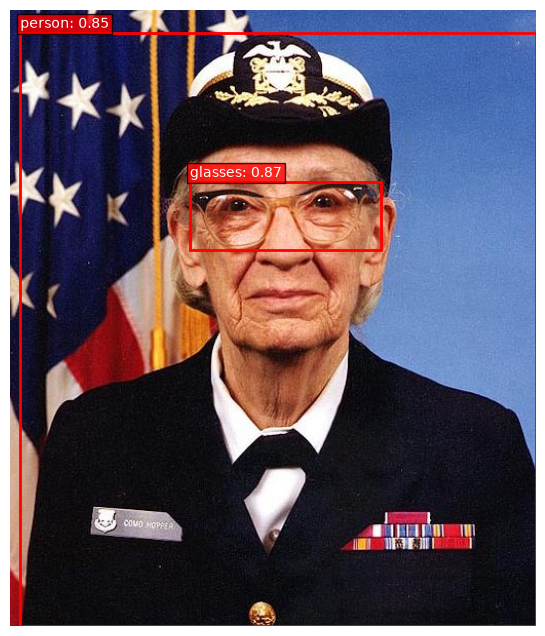

In [8]:
# 演習用: 値を変更して実行してください
exercise_prompt = "person. glasses."
exercise_box_threshold = 0.35
exercise_text_threshold = 0.25

exercise_result = detect_objects(
    image,
    exercise_prompt,
    exercise_box_threshold,
    exercise_text_threshold,
)
print("検出数:", len(exercise_result["boxes"]))
show_detections(image, exercise_result)

## まとめ

Grounding DINOは，学習時に固定されたクラス番号ではなく，文章で検出対象を指定できます．一方で，プロンプトや閾値によって結果が変わるため，目的に合わせた調整が必要です．